> **UNQUANTIZED RERUN** — generated copy of `19_e2b_rho_crossover.ipynb` with
> `meta-llama/Llama-3.1-8B-Instruct` (bf16, sharded via `device_map="auto"`)
> in place of the AWQ-INT4 variant. All `resources/` outputs carry the
> `_unquantized` suffix; the pair selection (`15_e0_selected_pairs.json`) is
> shared with the quantized runs so results are directly comparable.
> Hardcoded reference values quoted in comments/markdown still describe the
> AWQ runs. Original notebook left untouched.


# 19 — E2b: the ρ-adaptive crossover check

E2 found the aligned (GPA) mean beats the extrinsic mean at ρ=0.187 and loses at ρ≥0.321 — a proposed selection rule (aligned below a ρ threshold, extrinsic above) resting on one data point per side. This sweep runs **11 pairs spanning ρ 0.19–0.57** (dense in the (0.19, 0.32) window where the crossover must lie), extrinsic vs aligned only (E2 established frechet ≈ extrinsic), at the k=4 / steps=24 operating point.

Per-prompt paired gaps (both methods share prompts and baselines) give an error bar per pair. Deliverable: gap-vs-ρ curve + crossover estimate — or evidence the ρ story doesn't survive more pairs.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "meta-llama/Llama-3.1-8B-Instruct",
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24
METHODS = ("extrinsic", "aligned")

# from the Step-8 table (resources/15_e0_selected_pairs.json, all_pairs):
# the 3 E2 pairs for continuity + 8 more, dense where the crossover must lie.
# Hub pairs (woman/child, girl/child) excluded.
PAIR_NAMES = [
    ("sadness.n.01", "music.n.01"),
    ("joy.n.01", "music.n.01"),
    ("music.n.01", "water.n.01"),
    ("dog.n.01", "mathematics.n.01"),
    ("cat.n.01", "mathematics.n.01"),
    ("love.n.01", "hate.n.01"),
    ("woman.n.01", "king.n.01"),
    ("joy.n.01", "dog.n.01"),
    ("joy.n.01", "sorrow.n.01"),
    ("dog.n.01", "cat.n.01"),
    ("sorrow.n.01", "sadness.n.01"),
]

table = pd.DataFrame(
    json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["all_pairs"]
)
RHO = {(row["a"], row["b"]): row["rho"] for _, row in table.iterrows()}
REGIME = {(row["a"], row["b"]): row["regime"] for _, row in table.iterrows()}
assert all(
    pair in RHO for pair in PAIR_NAMES
), "all pairs must come from the Step-8 table"
for pair in PAIR_NAMES:
    print(f"rho={RHO[pair]:.3f}  {REGIME[pair]:>13}  {pair[0]} / {pair[1]}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


2026-07-16 23:35:03.761 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: meta-llama/Llama-3.1-8B-Instruct


2026-07-16 23:35:03.765 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 15316 Mb


rho=0.187      unrelated  sadness.n.01 / music.n.01
rho=0.230      unrelated  joy.n.01 / music.n.01
rho=0.271      unrelated  music.n.01 / water.n.01
rho=0.275      unrelated  dog.n.01 / mathematics.n.01
rho=0.284      unrelated  cat.n.01 / mathematics.n.01
rho=0.306        antonym  love.n.01 / hate.n.01
rho=0.321  compositional  woman.n.01 / king.n.01
rho=0.334      unrelated  joy.n.01 / dog.n.01
rho=0.355        antonym  joy.n.01 / sorrow.n.01
rho=0.394        similar  dog.n.01 / cat.n.01
rho=0.566        similar  sorrow.n.01 / sadness.n.01


## Pre-flight

The aligned mean requires equal effective ranks. Build all concepts and both means per pair up front; any pair that fails is excluded LOUDLY, not silently.

In [3]:
pairs = []
for name_a, name_b in PAIR_NAMES:
    concept_a = fur.get_concept_cached(name_a, MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(name_b, MIN_LEMMAS, MAX_TOKENS)
    try:
        guides = {
            method: Concept.average([concept_a, concept_b], method=method)
            for method in METHODS
        }
    except (ValueError, RuntimeError) as error:
        print(f"EXCLUDED {name_a} / {name_b}: {error}")
        continue
    pairs.append(
        {
            "a": name_a,
            "b": name_b,
            "rho": RHO[(name_a, name_b)],
            "regime": REGIME[(name_a, name_b)],
            "concept_a": concept_a,
            "concept_b": concept_b,
            "guides": guides,
        }
    )
print(f"{len(pairs)}/{len(PAIR_NAMES)} pairs ready")

11/11 pairs ready


In [4]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/19_e2b_crossover_unquantized.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:01<00:00,  1.56s/it]

100%|██████████| 1/1 [00:01<00:00,  1.56s/it]

baseline ready


In [5]:
for pair in pairs:
    synsets = [pair["a"], pair["b"]]
    concepts = {pair["a"]: pair["concept_a"], pair["b"]: pair["concept_b"]}
    for method in METHODS:
        texts, probe = fur.generate_with_topk_guide(
            PROMPTS, guide=pair["guides"][method], k=K, steps=STEPS
        )
        harness.evaluate(
            PROMPTS,
            texts,
            synsets,
            config={
                "pair": f"{pair['a']} / {pair['b']}",
                "rho": pair["rho"],
                "regime": pair["regime"],
                "method": method,
                "k": K,
                "steps": STEPS,
            },
            probe=probe,
            baseline_texts=baseline_texts,
            concepts=concepts,
        )
        print(f"rho={pair['rho']:.3f} {pair['a']} / {pair['b']} / {method}: done")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.75s/it]

100%|██████████| 1/1 [00:15<00:00, 15.75s/it]

rho=0.187 sadness.n.01 / music.n.01 / extrinsic: done


  0%|          | 0/1 [00:00<?, ?it/s]

...

rho=0.566 sorrow.n.01 / sadness.n.01 / extrinsic: done


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.89s/it]

100%|██████████| 1/1 [00:15<00:00, 15.89s/it]

rho=0.566 sorrow.n.01 / sadness.n.01 / aligned: done


In [6]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == len(pairs) * len(METHODS) * len(
    PROMPTS
), "one record per cell per prompt"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 440 records parse, expression logged


## Analysis

z-score each concept's delta across all its records (a concept can appear in several pairs — same concept, same scale), joint = min of the pair's two z-scores per record. The two methods share prompts, so the per-pair method gap is a *paired* difference with a standard error.

In [7]:
rows = []
for record in parsed:
    config = record["config"]
    name_a, name_b = config["pair"].split(" / ")
    expr = record["expression"]
    rows.append(
        {
            "pair": config["pair"],
            "rho": config["rho"],
            "regime": config["regime"],
            "method": config["method"],
            "prompt": record["prompt"],
            "concept_a": name_a,
            "concept_b": name_b,
            "delta_a": expr[name_a]["delta"],
            "delta_b": expr[name_b]["delta"],
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

# per-concept z across ALL records of that concept, regardless of pair or side
long = pd.concat(
    [
        results[["concept_a", "delta_a"]].rename(
            columns={"concept_a": "concept", "delta_a": "delta"}
        ),
        results[["concept_b", "delta_b"]].rename(
            columns={"concept_b": "concept", "delta_b": "delta"}
        ),
    ],
    keys=["a", "b"],
)
stats = long.groupby("concept")["delta"].agg(["mean", "std"])
for side in ("a", "b"):
    mu = results[f"concept_{side}"].map(stats["mean"])
    sd = results[f"concept_{side}"].map(stats["std"])
    results[f"z_{side}"] = (results[f"delta_{side}"] - mu) / (sd + 1e-8)
results["joint_z"] = results[["z_a", "z_b"]].min(axis=1)

summary = (
    results.groupby(["pair", "rho", "regime", "method"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint_z=("joint_z", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "method"])
)
summary.to_csv("resources/19_e2b_summary_unquantized.csv", index=False)
summary.round(4)

,pair,rho,regime,method,delta_a,delta_b,joint_z,ppl_ratio,flag_share
16,sadness.n.01 / music.n.01,0.1867,unrelated,aligned,0.7342,0.3825,-0.4232,6.3262,0.95
17,sadness.n.01 / music.n.01,0.1867,unrelated,extrinsic,0.8798,0.1905,-0.4126,8.1433,0.95
8,joy.n.01 / music.n.01,0.2301,unrelated,aligned,0.6264,0.4119,-0.2082,7.7671,0.95
9,joy.n.01 / music.n.01,0.2301,unrelated,extrinsic,0.5906,0.3640,-0.1786,7.3172,0.90
14,music.n.01 / water.n.01,0.2708,unrelated,aligned,0.2994,0.3031,-0.1946,7.2392,0.90
15,music.n.01 / water.n.01,0.2708,unrelated,extrinsic,0.2120,0.3315,-0.1996,6.9459,0.90
4,dog.n.01 / mathematics.n.01,0.2751,unrelated,aligned,0.4246,0.5714,-0.1616,7.7268,0.90
5,dog.n.01 / mathematics.n.01,0.2751,unrelated,extrinsic,0.3030,0.3127,-0.2879,7.4911,0.95
0,cat.n.01 / mathematics.n.01,0.2839,unrelated,aligned,0.5976,0.7761,-0.0089,7.2951,0.80
1,cat.n.01 / mathematics.n.01,0.2839,unrelated,extrinsic,0.5466,0.6262,-0.1200,7.0852,0.80


In [8]:
# paired per-prompt gap: joint_z(aligned) - joint_z(extrinsic) on the same prompt
wide = results.pivot_table(
    index=["pair", "rho", "regime", "prompt"], columns="method", values="joint_z"
).reset_index()
wide["gap"] = wide["aligned"] - wide["extrinsic"]

gaps = (
    wide.groupby(["pair", "rho", "regime"])["gap"]
    .agg(["mean", "sem", "count"])
    .reset_index()
    .sort_values("rho")
)
print(gaps.round(4).to_string(index=False))

# crossover estimate: zero-crossing of a weighted linear fit of gap vs rho
coeffs = np.polyfit(gaps["rho"], gaps["mean"], deg=1, w=1 / gaps["sem"])
crossover = -coeffs[1] / coeffs[0]
print(f"\nlinear fit: gap = {coeffs[0]:.3f} * rho + {coeffs[1]:.3f}")
print(f"zero crossing at rho = {crossover:.3f}")

                       pair    rho        regime    mean    sem  count
  sadness.n.01 / music.n.01 0.1867     unrelated -0.0106 0.1727     20
      joy.n.01 / music.n.01 0.2301     unrelated -0.0296 0.0835     20
    music.n.01 / water.n.01 0.2708     unrelated  0.0051 0.0804     20
dog.n.01 / mathematics.n.01 0.2751     unrelated  0.1264 0.1873     20
cat.n.01 / mathematics.n.01 0.2839     unrelated  0.1112 0.0504     20
      love.n.01 / hate.n.01 0.3060       antonym -0.0209 0.0321     20
     woman.n.01 / king.n.01 0.3213 compositional  0.2141 0.2434     20
        joy.n.01 / dog.n.01 0.3337     unrelated -0.0056 0.1578     20
     joy.n.01 / sorrow.n.01 0.3555       antonym -0.0590 0.0408     20
        dog.n.01 / cat.n.01 0.3939       similar  0.0102 0.0284     20
 sorrow.n.01 / sadness.n.01 0.5661       similar -0.0048 0.0062     20

linear fit: gap = -0.033 * rho + 0.013
zero crossing at rho = 0.412


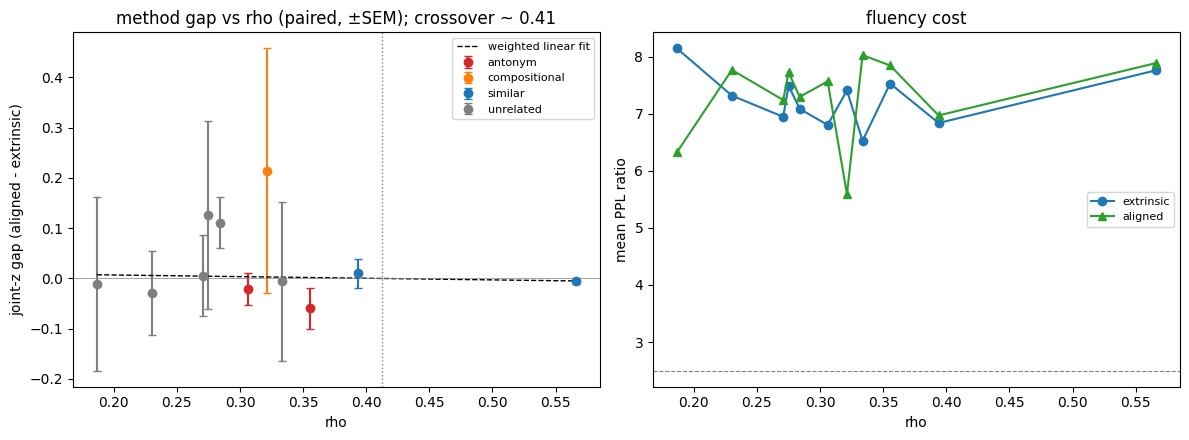

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

regime_colors = {
    "unrelated": "tab:gray",
    "antonym": "tab:red",
    "compositional": "tab:orange",
    "related": "tab:brown",
    "hypernym": "tab:green",
    "similar": "tab:blue",
}
for regime, group in gaps.groupby("regime"):
    axes[0].errorbar(
        group["rho"],
        group["mean"],
        yerr=group["sem"],
        fmt="o",
        color=regime_colors.get(regime, "black"),
        label=regime,
        capsize=3,
    )
fit_x = np.linspace(gaps["rho"].min(), gaps["rho"].max(), 50)
axes[0].plot(fit_x, np.polyval(coeffs, fit_x), "k--", lw=1, label="weighted linear fit")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].axvline(crossover, color="gray", ls=":", lw=1)
axes[0].set_xlabel("rho")
axes[0].set_ylabel("joint-z gap (aligned - extrinsic)")
axes[0].set_title(f"method gap vs rho (paired, ±SEM); crossover ~ {crossover:.2f}")
axes[0].legend(fontsize=8)

ppl = summary.pivot_table(index="rho", columns="method", values="ppl_ratio")
axes[1].plot(ppl.index, ppl["extrinsic"], "o-", color="tab:blue", label="extrinsic")
axes[1].plot(ppl.index, ppl["aligned"], "^-", color="tab:green", label="aligned")
axes[1].axhline(2.5, color="gray", ls="--", lw=0.8)
axes[1].set_xlabel("rho")
axes[1].set_ylabel("mean PPL ratio")
axes[1].set_title("fluency cost")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("resources/19_e2b_gap_vs_rho_unquantized.png", dpi=150)
plt.show()

In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for pair in (pairs[0], pairs[3], pairs[-1]):
    key = f"{pair['a']} / {pair['b']}"
    for method in METHODS:
        example = next(
            r
            for r in parsed
            if r["config"]["pair"] == key
            and r["config"]["method"] == method
            and "short story" in r["prompt"]
        )
        deltas = {
            name.split(".")[0]: round(v["delta"], 4)
            for name, v in example["expression"].items()
        }
        print(f"[rho={pair['rho']:.3f} {key} / {method}] deltas={deltas}")
        print("   ", answer(example["text"])[:130])
    print()

[rho=0.187 sadness.n.01 / music.n.01 / extrinsic] deltas={'sadness': -0.3676, 'music': -1.4527}
    Once, a small wooden bird perished in its owner a kind and old clock. For years, its intricate carvins and
[rho=0.187 sadness.n.01 / music.n.01 / aligned] deltas={'sadness': 0.087, 'music': -0.6858}
    Once, a small wooden bird perished in its nest. Its delicate wings had never known wind, and its bright song remained silent

[rho=0.275 dog.n.01 / mathematics.n.01 / extrinsic] deltas={'dog': 0.6503, 'mathematics': 1.3386}
    Once, in Japan during the Cherry Blosson Season (, or "sakura season,"), in Tokyo, in Uehara
[rho=0.275 dog.n.01 / mathematics.n.01 / aligned] deltas={'dog': 0.3361, 'mathematics': 0.6604}
    Once, in Japan during cherry bloom season (SakURA-michi) in April of that year. A quiet old tea house

[rho=0.566 sorrow.n.01 / sadness.n.01 / extrinsic] deltas={'sorrow': -0.715, 'sadness': -0.3258}
    Once, on an old and cypress-shrouds island off Louisiana coast line ther